# MS-DSA-NET — этапы 0 и 1: проверка конвейера на UHB и улучшения без обучения

**Этап 0. Проверка конвейера на данных, на которых модель обучалась (Bonn/UHB, ds004199, 85 FCD II).**
Это не тест модели: 68 из 85 пациентов были в обучении. Если наш конвейер воспроизводит оригинал, sSens здесь должен быть высоким (≳0.8) при единицах ложных кластеров.
Если нет — ошибка у нас (регистрация, нормализация, каналы), и улучшать модель рано.
Заодно препроцессинг UHB понадобится для гармонизации (этап 1) и дообучения (этап 2).

**Этап 1. Улучшения без обучения на IDEAS (34 FCD с FLAIR)**
1. Постобработка готовых карт вероятности: маска мозга (BET), фильтр мелких кластеров, top-K кластеров, порог.
2. Гармонизация интенсивностей: Nyúl (выравнивание гистограммы мозга к UHB), N4 + Nyúl.
3. TTA — усреднение по 8 отражениям.

⚠️ Параметры подбираются на тех же 34 пациентах, на которых и меряются, — результат этапа 1 оптимистичен.
Честная оценка — на этапе 2 (кросс-валидация, параметры выбираются только на обучающих фолдах).

**Нужно:** `msdsa_lib.py` рядом с этим ноутбуком (или в `~/projects/mri/ms_dsa_net`); для N4 — `~/.local/bin/uv pip install SimpleITK`.
**Время:** этап 0 ≈ 20–30 мин (скачивание ~3 ГБ + FSL), этап 1 ≈ 30–40 мин (с N4).

## 1. Конфигурация  
После изменения параметров — Kernel → Restart и запуск с этой ячейки.

In [2]:
import os, sys, time, subprocess
from pathlib import Path

os.nice(15)                                    # низкий приоритет CPU для ядра и всех процессов FSL
try:
    import psutil; psutil.Process().ionice(psutil.IOPRIO_CLASS_IDLE)
except Exception as e: print("ionice:", e)

FSLDIR, VENV_BIN = Path.home() / "fsl", Path(sys.executable).parent
os.environ.update(FSLDIR=str(FSLDIR), FSLOUTPUTTYPE="NIFTI_GZ")
_p = [p for p in os.environ["PATH"].split(":") if p and p not in (str(VENV_BIN), f"{FSLDIR}/bin", f"{FSLDIR}/share/fsl/bin")]
os.environ["PATH"] = ":".join([str(VENV_BIN)] + _p + [f"{FSLDIR}/share/fsl/bin", f"{FSLDIR}/bin"])

PROJ    = Path.home() / "projects/mri/ms_dsa_net"
REPO    = PROJ / "MS-DSA-NET"
WEIGHTS = REPO / "pretrained/model.pth"
MNI     = REPO / "inputs/MNI152_T1_1mm.nii.gz"
META_CSV  = PROJ / "data/ideas_meta/Metadata_Release_Anon.csv"
MASKS_DIR = PROJ / "data/ideas_masks"

# ресурсы (сервер общий)
GPU_ID, GPU_MEM_BUDGET_GB = 1, 10      
GPU_TEMP_PAUSE, GPU_TEMP_RESUME = 83, 75
MAX_CPU   = 8                           # сколько ядер можно занять
N_FSL     = max(1, MAX_CPU * 2 // 3)    # FSL-задач одновременно (каждая ~1.5 ядра)
N_DOWNLOAD, PREFETCH = 4, 3
RUN_N4    = True                        # нужен SimpleITK; False — пропустить варианты с N4
PATCH, OVERLAP = (128, 128, 128), 0.25  # из оригинала

os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID)
for p in (Path.cwd(), PROJ):
    if (p / "msdsa_lib.py").exists() and str(p) not in sys.path: sys.path.insert(0, str(p))
import msdsa_lib as ml
print("nice =", os.nice(0), "| GPU", GPU_ID, "| FSL-задач:", N_FSL, "| msdsa_lib:", ml.__file__)

nice = 19 | GPU 1 | FSL-задач: 5 | msdsa_lib: /home/trocinskayayv/projects/mri/notebooks/msdsa_lib.py


## 2. Проверка окружения

In [3]:
import shutil, numpy as np, pandas as pd, nibabel as nib, torch, monai
import matplotlib.pyplot as plt
torch.set_num_threads(2)
print("torch", torch.__version__, "| monai", monai.__version__, "| CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0))
for tool in ["fslreorient2std", "robustfov", "flirt", "convert_xfm", "bet", "aws"]:
    print(f"{tool:16s}", shutil.which(tool) or "НЕ НАЙДЕН")
try:
    import SimpleITK; print("SimpleITK        ", SimpleITK.Version_VersionString())
except ImportError:
    RUN_N4 = False; print("SimpleITK        нет → варианты с N4 пропускаются (установить: ~/.local/bin/uv pip install SimpleITK)")
assert all(shutil.which(t) for t in ["flirt", "robustfov", "fslreorient2std", "convert_xfm", "bet", "aws"])

torch 2.0.1+cu117 | monai 1.2.0 | CUDA: True NVIDIA RTX A4000
fslreorient2std  /home/trocinskayayv/fsl/bin/fslreorient2std
robustfov        /home/trocinskayayv/fsl/bin/robustfov
flirt            /home/trocinskayayv/fsl/bin/flirt
convert_xfm      /home/trocinskayayv/fsl/bin/convert_xfm
bet              /home/trocinskayayv/fsl/bin/bet
aws              /home/trocinskayayv/envs/ms_dsa/bin/aws
SimpleITK        нет → варианты с N4 пропускаются (установить: ~/.local/bin/uv pip install SimpleITK)


## 3. Модель, контроль температуры, `SW_BATCH`

In [4]:
def gpu_temp():
    out = subprocess.run(["nvidia-smi", "-i", str(GPU_ID), "--query-gpu=temperature.gpu", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.strip()
    return int(out) if out.isdigit() else -1

def wait_cool():
    if gpu_temp() >= GPU_TEMP_PAUSE:
        print(f"\nGPU {gpu_temp()}°C — пауза", flush=True)
        while gpu_temp() > GPU_TEMP_RESUME: time.sleep(15)

sys.path.insert(0, str(REPO))
from networks2 import MS_DSA_NET
from monai.inferers import sliding_window_inference
device = torch.device("cuda")
model = MS_DSA_NET(spatial_dims=3, in_channels=2, out_channels=2, img_size=list(PATCH), feature_size=16, pos_embed=True,
                   project_size=64, sa_type="parallel", norm_name="instance",
                   act_name=("leakyrelu", {"inplace": True, "negative_slope": 0.01}), res_block=True, bias=False, dropout_rate=0.1)
sd = torch.load(WEIGHTS, map_location="cpu")
sd = sd.get("state_dict", sd); sd = {k.replace("module.", "", 1): v for k, v in sd.items()}
model.load_state_dict(sd, strict=True); model.to(device).eval()
torch.backends.cudnn.benchmark = True

def run_sw(x, sw):
    with torch.no_grad():
        return sliding_window_inference(x, PATCH, sw, model, overlap=OVERLAP)

SW_BATCH = 4          # подобрано в основном ноутбуке (0.45 с/объём, 4.8 ГБ)
infer_base = ml.make_infer(run_sw, device, SW_BATCH, tta=False)
infer_tta  = ml.make_infer(run_sw, device, SW_BATCH, tta=True)
print("Модель готова, GPU", gpu_temp(), "°C")

Модель готова, GPU 38 °C


# Этап 0. Проверка конвейера на UHB (ds004199)
Маски UHB нарисованы на FLAIR (`gt_space="flair"`), как в оригинальном `preprocess_data.py`.

In [5]:
UHB = ml.Dataset("UHB", "ds004199", PROJ / "data/ds004199", PROJ / "work_uhb", PROJ / "outputs_uhb", gt_space="flair")
uhb_keys = ml.s3_index(UHB.s3_id, UHB.data_dir / "_s3_index.txt")
UHB.files = ml.index_with_masks_in_s3(uhb_keys)
print(f"Ключей в S3: {len(uhb_keys)} | пациентов с маской: {len(UHB.files)} (ожидается 85)")
fdf = pd.DataFrame.from_dict(UHB.files, orient="index")
print("Несколько T1/FLAIR/масок у пациента:", fdf[(fdf.n_t1 > 1) | (fdf.n_flair > 1) | (fdf.n_mask > 1)].index.tolist()[:10])
s0 = next(iter(UHB.files))
print(f"\nФайлы {s0} в S3:"); print("\n".join(k for k in uhb_keys if f"/{s0}/" in k))
print("\nВыбрано:", {k: Path(v).name for k, v in UHB.files[s0].items() if isinstance(v, str)})

Ключей в S3: 773 | пациентов с маской: 85 (ожидается 85)
Несколько T1/FLAIR/масок у пациента: []

Файлы sub-00001 в S3:
ds004199/sub-00001/anat/sub-00001_acq-T2sel_FLAIR.json
ds004199/sub-00001/anat/sub-00001_acq-T2sel_FLAIR.nii.gz
ds004199/sub-00001/anat/sub-00001_acq-T2sel_FLAIR_roi.nii.gz
ds004199/sub-00001/anat/sub-00001_acq-iso08_T1w.json
ds004199/sub-00001/anat/sub-00001_acq-iso08_T1w.nii.gz

Выбрано: {'t1': 'sub-00001_acq-iso08_T1w.nii.gz', 'flair': 'sub-00001_acq-T2sel_FLAIR.nii.gz', 'mask': 'sub-00001_acq-T2sel_FLAIR_roi.nii.gz'}


Проверьте выбор файлов выше (T1w, FLAIR, маска к этому FLAIR). Если пациентов 0 или маска не та — пришлите вывод, поправлю индекс.

In [6]:
uhb_subjects = sorted(UHB.files)
r_uhb = ml.run_pipeline(UHB, uhb_subjects, infer=infer_base, variant="base", mni=MNI,
                        n_download=N_DOWNLOAD, n_fsl=N_FSL, prefetch=PREFETCH, wait_cool=wait_cool)
if r_uhb["failures"]: display(pd.Series(r_uhb["failures"], name="ошибка"))

base: 1 download:   0%|          | 0/85 [00:00<?, ?it/s]

base: 2 FSL:   0%|          | 0/85 [00:00<?, ?it/s]

base: 3 GPU:   0%|          | 0/85 [00:00<?, ?it/s]

base: 4 save:   0%|          | 0/85 [00:00<?, ?it/s]

[UHB/base] 30.9 мин | готово 85 | ошибок 0


In [7]:
ev_uhb = ml.evaluate(UHB.pred("base"), UHB.ref, r_uhb["done"], [ml.Post()])
s_uhb = ml.summarize(ev_uhb)
display(s_uhb)
print("Статья (UHB test, n=17):", ml.PAPER)
row = s_uhb.iloc[0]
if row.sSens >= 0.75 and row.nFPC <= 3:
    print("\n✅ Конвейер воспроизводит модель на её домене → падение на IDEAS — это сдвиг домена. Переходим к этапу 1.")
else:
    print("\n❌ На обучающих данных результат слабый → вероятна ошибка в нашем конвейере. "
          "Этап 1 не запускайте, пришлите вывод этой ячейки и картинки ниже.")

/home/trocinskayayv/projects/mri/notebooks/msdsa_lib.py:520: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(list(by), sort=False).apply(agg).round(3)


,n,sSens,sSens_CI,top1,nFPC,nFPC_med,noFP_%,PPV_cl,Dice,Prec,out_brain_%
post,,,,,,,,,,,
thr=0.5,85,0.906,0.83–0.95,0.894,0.459,0.0,76.471,0.695,0.676,0.743,9.375


Статья (UHB test, n=17): {'sSens': 0.824, 'nFPC': 0.176, 'Dice': 0.41, 'Sens': 0.438, 'Prec': 0.481}

✅ Конвейер воспроизводит модель на её домене → падение на IDEAS — это сдвиг домена. Переходим к этапу 1.


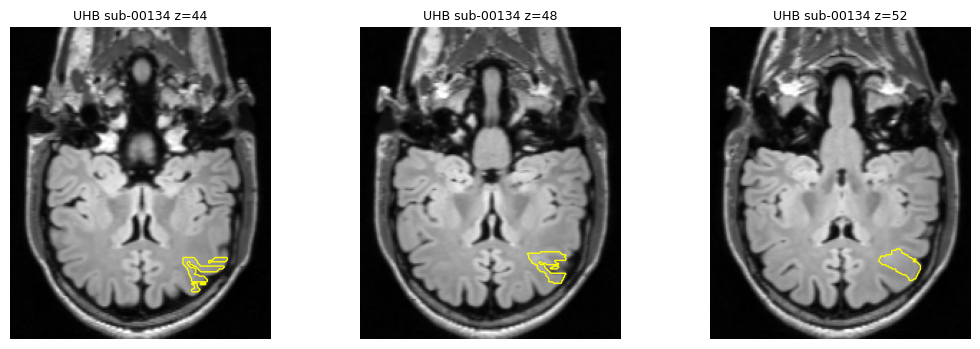

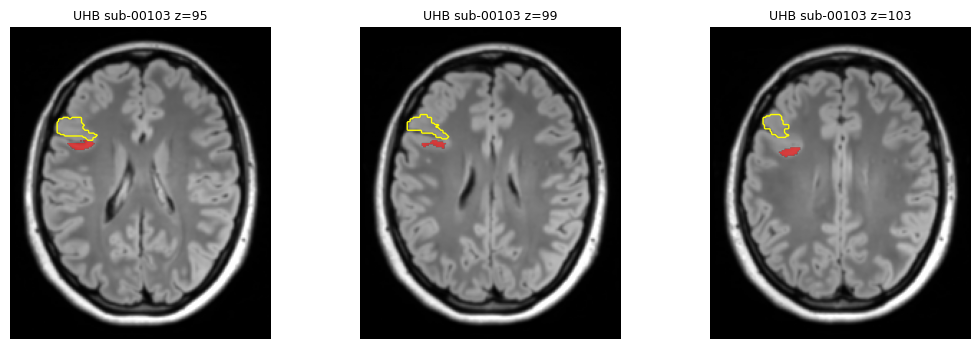

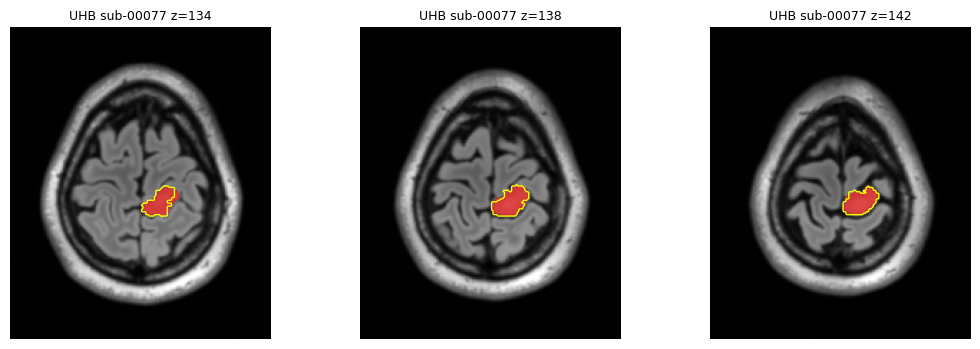

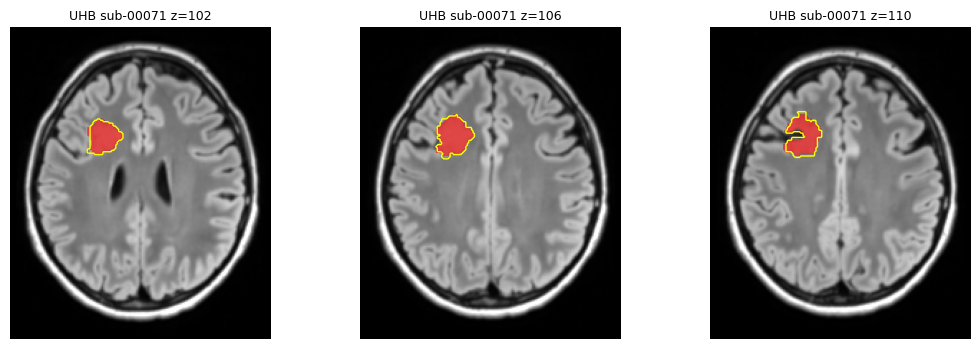

In [8]:
def show(ds, variant, sub, n=3):
    x, _, _, _ = ml.load_arrays(ds, sub)
    gt = nib.load(ds.ref / f"{sub}_gt.nii.gz").get_fdata() > 0
    seg = nib.load(ds.pred(variant) / f"{sub}_prob.nii.gz").get_fdata() >= 0.5
    zc = int(np.argwhere(gt | seg)[:, 2].mean()) if (gt | seg).any() else x.shape[3] // 2
    fig, ax = plt.subplots(1, n, figsize=(3.6 * n, 3.6))
    for i, z in enumerate(range(zc - 4 * (n // 2), zc + 4 * (n // 2) + 1, 4)):
        ax[i].imshow(np.rot90(x[1, :, :, z]), cmap="gray"); ax[i].contour(np.rot90(gt[:, :, z]), colors="yellow", linewidths=1)
        ax[i].imshow(np.rot90(np.ma.masked_where(~seg[:, :, z], seg[:, :, z])), cmap="autumn", alpha=0.6)
        ax[i].set_title(f"{ds.name} {sub} z={z}", fontsize=9); ax[i].axis("off")
    plt.tight_layout(); plt.show()

e = ev_uhb.sort_values("Dice")
for s in e["sub"].head(2).tolist() + e["sub"].tail(2).tolist(): show(UHB, "base", s)

# Этап 1. Улучшения без обучения (IDEAS)
## 1.1. Подготовка: маски мозга и эталоны для уже посчитанной базовой версии
Используются результаты основного ноутбука (`work/`, `outputs/pred`). Новый препроцессинг не нужен — только BET (~10 с на пациента).

In [9]:
meta = pd.read_csv(META_CSV); meta["sub"] = "sub-" + meta["ID"].astype(str)
meta = meta.drop_duplicates("sub").set_index("sub")
ideas_fcd = meta.index[meta.Pathology == "FCD"].tolist()

def ideas_mask(sub):
    n = sub.replace("sub-", ""); p = MASKS_DIR / "masks" / n / f"{n}_MaskInRawData.nii.gz"
    return p if p.exists() else None

IDEAS = ml.Dataset("IDEAS", "ds005602", PROJ / "data/ds005602", PROJ / "work", PROJ / "outputs", gt_space="t1")
IDEAS.files = ml.index_with_local_masks(ml.s3_index(IDEAS.s3_id, IDEAS.data_dir / "_s3_index.txt"), ideas_fcd, ideas_mask)
ideas_subjects = [s for s in ideas_fcd if (IDEAS.fsl(s) / "flair_reg.nii.gz").exists()]
print(f"FCD: {len(ideas_fcd)} | с готовым препроцессингом: {len(ideas_subjects)}")

from concurrent.futures import ThreadPoolExecutor
def prep_refs(ds, sub):
    try: ml.ensure_brain(ds, sub); ml.export_refs(ds, sub); return None
    except Exception as e: return f"{sub}: {e}"
for ds, subs in ((IDEAS, ideas_subjects), (UHB, r_uhb["done"])):
    with ThreadPoolExecutor(N_FSL) as ex: errs = [e for e in ex.map(lambda s: prep_refs(ds, s), subs) if e]
    print(ds.name, "маски мозга готовы; ошибки:", errs or "нет")

FCD: 39 | с готовым препроцессингом: 34
IDEAS маски мозга готовы; ошибки: нет
UHB маски мозга готовы; ошибки: нет


## 1.2. Протоколы сканирования IDEAS и связь с пропусками

In [10]:
import json as _json
base_ev = ml.evaluate(IDEAS.pred("pred"), IDEAS.ref, ideas_subjects, [ml.Post()]).set_index("sub")
rows = []
for s in ideas_subjects:
    r = {"sub": s, "subtype": str(meta.loc[s, "OP MEMO"])[:12], "detected": base_ev.loc[s, "detected"] if s in base_ev.index else np.nan}
    for kind, key in (("T1", IDEAS.files[s]["t1"]), ("FLAIR", IDEAS.files[s]["flair"])):
        p = ml._local(IDEAS, key)
        r[f"{kind}_vox"] = "×".join(f"{z:.2g}" for z in nib.load(p).header.get_zooms()[:3])
        j = p.with_name(p.name.replace(".nii.gz", ".json"))
        if j.exists():
            js = _json.loads(j.read_text())
            r[f"{kind}_model"] = js.get("ManufacturersModelName", js.get("Manufacturer", "?"))
            if kind == "FLAIR": r["FLAIR_3D"] = js.get("MRAcquisitionType", "?")
    rows.append(r)
scan = pd.DataFrame(rows).set_index("sub")
display(scan)
for c in ["FLAIR_vox", "FLAIR_model", "FLAIR_3D"]:
    if c in scan: display(scan.groupby(c).detected.agg(["size", "mean"]).rename(columns={"size": "n", "mean": "sSens"}).round(2))

,subtype,detected,T1_vox,T1_model,FLAIR_vox,FLAIR_model,FLAIR_3D
sub,,,,,,,
sub-30,type IIB,1,0.94×1.1×0.94,SIGNA HDx,0.94×0.94×3.5,SIGNA HDx,?
sub-34,type IIB,1,0.94×1.5×0.94,SIGNA HDx,0.94×0.94×5,SIGNA HDx,?
sub-83,type IIB,1,1×1×1,DISCOVERY MR750,1×1×1,DISCOVERY MR750,?
sub-86,type IIB,1,1.1×1.2×1.1,DISCOVERY MR750,0.94×2×0.94,DISCOVERY MR750,?
sub-100,type IIB,1,0.94×1.1×0.94,SIGNA HDx,0.94×0.94×3.5,SIGNA HDx,?
sub-103,type IIA,0,1×1×1,DISCOVERY MR750,1×1×1,DISCOVERY MR750,?
sub-110,type IIB,0,0.94×1.1×0.94,SIGNA HDx,0.94×0.94×5,SIGNA HDx,?
sub-116,type IIB,1,1×1×1,DISCOVERY MR750,1×1×1,DISCOVERY MR750,?
sub-128,type IIA,0,0.94×1.1×0.94,SIGNA HDx,0.94×0.94×5,SIGNA HDx,?


,n,sSens
FLAIR_vox,,
0.94×0.94×3,4,0.50
0.94×0.94×3.5,5,0.60
0.94×0.94×5,17,0.18
0.94×2×0.94,2,0.50
1×1×1,6,0.67


,n,sSens
FLAIR_model,,
DISCOVERY MR750,8,0.62
SIGNA EXCITE,4,0.25
SIGNA HDx,22,0.32


,n,sSens
FLAIR_3D,,
?,34,0.38


## 1.3. Постобработка базовых предсказаний
`+brain` — вероятность вне маски мозга (BET, расширенной на 3 мм) обнуляется; `≥N` — убрать кластеры меньше N мм³; `topK` — оставить K самых уверенных кластеров.
`out_brain_%` у базовой строки — доля кластеров с пиком вне мозга: показывает, откуда ложные срабатывания.

In [11]:
POSTS = [ml.Post(thr=t, brain=b, min_vox=v, topk=k)
         for t in (0.5, 0.7, 0.9) for b in (False, True) for v in (0, 100) for k in (None, 3, 1)]
ev_post = ml.evaluate(IDEAS.pred("pred"), IDEAS.ref, ideas_subjects, POSTS)
s_post = ml.summarize(ev_post)
pd.set_option("display.max_rows", 100)
display(s_post.sort_values(["nFPC"]).style.background_gradient(subset=["sSens", "top1"], cmap="Greens")
        .background_gradient(subset=["nFPC"], cmap="Reds"))
print("На UHB (не должна заметно ухудшать свой домен):")
display(ml.summarize(ml.evaluate(UHB.pred("base"), UHB.ref, r_uhb["done"],
                                 [ml.Post(), ml.Post(brain=True, min_vox=100), ml.Post(brain=True, min_vox=100, topk=3)])))

/home/trocinskayayv/projects/mri/notebooks/msdsa_lib.py:520: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(list(by), sort=False).apply(agg).round(3)


,n,sSens,sSens_CI,top1,nFPC,nFPC_med,noFP_%,PPV_cl,Dice,Prec,out_brain_%
post,,,,,,,,,,,
thr=0.9 +brain ≥100 top1,34,0.176000,0.08–0.34,0.176000,0.382000,0.000000,61.765000,0.316000,0.027000,0.257000,0.000000
thr=0.7 +brain ≥100 top1,34,0.206000,0.10–0.37,0.206000,0.412000,0.000000,58.824000,0.333000,0.028000,0.260000,0.000000
thr=0.9 ≥100 top1,34,0.176000,0.08–0.34,0.176000,0.471000,0.000000,52.941000,0.273000,0.027000,0.222000,13.636000
thr=0.5 +brain ≥100 top1,34,0.206000,0.10–0.37,0.206000,0.471000,0.000000,52.941000,0.304000,0.029000,0.230000,0.000000
thr=0.7 ≥100 top1,34,0.206000,0.10–0.37,0.206000,0.529000,1.000000,47.059000,0.280000,0.028000,0.218000,16.000000
thr=0.5 ≥100 top1,34,0.206000,0.10–0.37,0.206000,0.588000,1.000000,41.176000,0.259000,0.029000,0.196000,14.815000
thr=0.9 +brain top1,34,0.206000,0.10–0.37,0.206000,0.618000,1.000000,38.235000,0.250000,0.027000,0.205000,3.571000
thr=0.7 +brain top1,34,0.206000,0.10–0.37,0.206000,0.706000,1.000000,29.412000,0.226000,0.028000,0.176000,6.452000
thr=0.9 +brain ≥100 top3,34,0.294000,0.17–0.46,0.176000,0.706000,0.000000,58.824000,0.314000,0.032000,0.296000,2.857000


На UHB (не должна заметно ухудшать свой домен):


/home/trocinskayayv/projects/mri/notebooks/msdsa_lib.py:520: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(list(by), sort=False).apply(agg).round(3)


,n,sSens,sSens_CI,top1,nFPC,nFPC_med,noFP_%,PPV_cl,Dice,Prec,out_brain_%
post,,,,,,,,,,,
thr=0.5,85,0.906,0.83–0.95,0.894,0.459,0.0,76.471,0.695,0.676,0.743,9.375
thr=0.5 +brain ≥100,85,0.906,0.83–0.95,0.894,0.059,0.0,94.118,0.939,0.677,0.763,1.220
thr=0.5 +brain ≥100 top3,85,0.906,0.83–0.95,0.894,0.059,0.0,94.118,0.939,0.677,0.763,1.220


## 1.4. Гармонизация и TTA — новые варианты инференса на IDEAS
Эталон Nyúl — средние ориентиры гистограммы мозга по пациентам UHB (после той же нормализации, что видит сеть).

In [12]:
ref_plain, n_ref = ml.nyul_reference(UHB, r_uhb["done"])
print("Эталон Nyúl (UHB):", n_ref, "пациентов")
VARIANTS = {"tta": dict(infer=infer_tta),
            "nyul": dict(infer=infer_base, harmonizer=ml.Nyul(ref_plain)),
            "nyul_tta": dict(infer=infer_tta, harmonizer=ml.Nyul(ref_plain))}
if RUN_N4:
    with ThreadPoolExecutor(N_FSL) as ex: list(ex.map(lambda s: ml.ensure_n4(UHB, s), r_uhb["done"]))
    ref_n4, _ = ml.nyul_reference(UHB, r_uhb["done"], n4=True)
    VARIANTS["n4_nyul"] = dict(infer=infer_base, harmonizer=ml.Nyul(ref_n4), n4=True)
    VARIANTS["n4_nyul_tta"] = dict(infer=infer_tta, harmonizer=ml.Nyul(ref_n4), n4=True)

runs = {}
for name, kw in VARIANTS.items():
    runs[name] = ml.run_pipeline(IDEAS, ideas_subjects, variant=name, mni=MNI, n_fsl=N_FSL, prefetch=PREFETCH,
                                 wait_cool=wait_cool, **kw)

Эталон Nyúl (UHB): 85 пациентов


tta: 1 download:   0%|          | 0/34 [00:00<?, ?it/s]

tta: 2 FSL:   0%|          | 0/34 [00:00<?, ?it/s]

tta: 3 GPU:   0%|          | 0/34 [00:00<?, ?it/s]

tta: 4 save:   0%|          | 0/34 [00:00<?, ?it/s]


GPU 81°C — пауза

GPU 83°C — пауза

GPU 81°C — пауза

GPU 84°C — пауза
[IDEAS/tta] 3.2 мин | готово 34 | ошибок 0


... (6 outputs left out)

nyul_tta: 2 FSL:   0%|          | 0/34 [00:00<?, ?it/s]

nyul_tta: 3 GPU:   0%|          | 0/34 [00:00<?, ?it/s]

nyul_tta: 4 save:   0%|          | 0/34 [00:00<?, ?it/s]


GPU 83°C — пауза

GPU 81°C — пауза

GPU 82°C — пауза

GPU 82°C — пауза

GPU 83°C — пауза

GPU 81°C — пауза

GPU 82°C — пауза
[IDEAS/nyul_tta] 4.0 мин | готово 34 | ошибок 0


## 1.5. Сравнение вариантов

/home/trocinskayayv/projects/mri/notebooks/msdsa_lib.py:520: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(list(by), sort=False).apply(agg).round(3)


/home/trocinskayayv/projects/mri/notebooks/msdsa_lib.py:520: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby(list(by), sort=False).apply(agg).round(3)


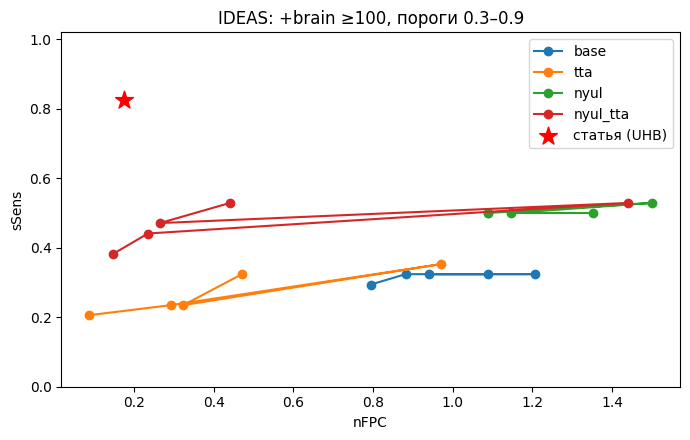

Сохранено: outputs/stage1_comparison.csv, stage1_per_subject.csv, stage1_froc.png


In [13]:
CMP_POSTS = [ml.Post(), ml.Post(brain=True, min_vox=100), ml.Post(brain=True, min_vox=100, topk=3),
             ml.Post(thr=0.7, brain=True, min_vox=100)]
SWEEP = [ml.Post(thr=t, brain=True, min_vox=100) for t in (0.3, 0.5, 0.7, 0.8, 0.9)]
ev_all = []
for v in ["pred"] + list(VARIANTS):
    e = ml.evaluate(IDEAS.pred(v), IDEAS.ref, ideas_subjects, list(dict.fromkeys(CMP_POSTS + SWEEP))); e["variant"] = "base" if v == "pred" else v
    ev_all.append(e)
ev_all = pd.concat(ev_all)
cmp = ml.summarize(ev_all[ev_all.post.isin([p.label for p in CMP_POSTS])], by=("variant", "post"))
display(cmp.style.background_gradient(subset=["sSens", "top1"], cmap="Greens").background_gradient(subset=["nFPC"], cmap="Reds"))

sw = ml.summarize(ev_all[ev_all.post.isin([p.label for p in SWEEP])], by=("variant", "post")).reset_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
for v, d in sw.groupby("variant", sort=False):
    ax.plot(d.nFPC, d.sSens, "o-", label=v)
ax.scatter([ml.PAPER["nFPC"]], [ml.PAPER["sSens"]], marker="*", s=180, c="red", label="статья (UHB)")
ax.set_xlabel("nFPC"); ax.set_ylabel("sSens"); ax.set_ylim(0, 1.02); ax.set_title("IDEAS: +brain ≥100, пороги 0.3–0.9"); ax.legend()
plt.tight_layout(); plt.savefig(IDEAS.out_dir / "stage1_froc.png", dpi=110); plt.show()

cmp.to_csv(IDEAS.out_dir / "stage1_comparison.csv"); ev_all.to_csv(IDEAS.out_dir / "stage1_per_subject.csv", index=False)
print("Сохранено: outputs/stage1_comparison.csv, stage1_per_subject.csv, stage1_froc.png")